# Part 1 - Read an external data source

In [1]:
import numpy as np
import pandas as pd
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

Fanaee-T, H. (2013). Bike Sharing [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5W894.

In [2]:
bike_raw = pd.read_csv("../data/data_raw/day.csv", parse_dates = ["dteday"])
bike_raw.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
bike_raw.shape

(731, 16)

In [4]:
bike_raw.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

In [5]:
bike_raw.dtypes

instant                int64
dteday        datetime64[us]
season                 int64
yr                     int64
mnth                   int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

In [6]:
bike_raw.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

There are no missing values in this particular data set

In [7]:
bike_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

In [8]:
bike_raw.describe()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


# Part 2 - Modular cleaning

In [9]:
sys.path.append(str(Path("..").resolve()))

from src.cleaning_functions import remove_na
from src.cleaning_functions import select_cols
from src.cleaning_functions import absolute_temp
from src.cleaning_functions import working_day

In [10]:
bike_remove_na = remove_na(bike_raw)

In [11]:
bike_select_cols = select_cols(bike_remove_na)

In [12]:
bike_absolute_temp = absolute_temp(bike_select_cols)

In [13]:
bike_analysis = working_day(bike_absolute_temp)
bike_analysis.head()

,cnt,temp,workingday,abs_temp,work_day
0,985,0.344167,0,8.175849,Not work day
1,801,0.363478,0,9.083466,Not work day
2,1349,0.196364,1,1.229108,Work day
3,1562,0.200000,1,1.400000,Work day
4,1600,0.226957,1,2.666979,Work day


In [14]:
bike_analysis.describe(include = "all")

,cnt,temp,workingday,abs_temp,work_day
count,731.000000,731.000000,731.000000,731.000000,731
unique,NaN,NaN,NaN,NaN,2
top,NaN,NaN,NaN,NaN,Work day
freq,NaN,NaN,NaN,NaN,500
mean,4504.348837,0.495385,0.683995,15.283085,NaN
std,1937.211452,0.183051,0.465233,8.603397,NaN
min,22.000000,0.059130,0.000000,-5.220871,NaN
25%,3152.000000,0.337083,0.000000,7.842925,NaN
50%,4548.000000,0.498333,1.000000,15.421651,NaN
75%,5956.000000,0.655417,1.000000,22.804575,NaN


# Part 3 - Exploratory analysis

## Question 1: Is there an association between the temperature in celsius, and the amount of bikes rented out on a given day?

In [15]:
temp_cnt_corr = round(float(bike_analysis["abs_temp"].corr(bike_analysis["cnt"])), 5)
temp_cnt_corr

0.62749

In [16]:
slope, intercept = np.polyfit(bike_analysis["abs_temp"], bike_analysis["cnt"], 1)

float(slope), float(intercept)

(141.29170209677946, 2344.9757358036386)

From this correlation coefficient, we can see that there is a fairly moderate, positive, linear association, between the temperature in celsius and the amount of bike rentals on a given day. From the numpy polyfit call, we can also see that the slope of the association between temperature and bike rentals is approximately 141.29, which means that for a 1 degree Celsius increase in temperature, the amount of bike rentals per day is expected to increase by about 141.29 on average. The intercept of the association is approximately 2344.98, which means that at a temperature of 0 degrees Celsius, the expected amount of bike rentals per day is approximately 2344.98.

## Question 2: Does the status of workday (do people have work on a given day or not) affect rental bike counts?

In [17]:
wrkdy_cnt_corr = round(float(bike_analysis["workingday"].corr(bike_analysis["cnt"])), 5)
wrkdy_cnt_corr

0.06116

In [18]:
work_day_mean = float(bike_analysis.loc[bike_analysis["work_day"] == "Work day", "cnt"].mean())
not_work_day_mean = float(bike_analysis.loc[bike_analysis["work_day"] == "Not work day", "cnt"].mean())

work_day_mean, not_work_day_mean

(4584.82, 4330.168831168831)

In [19]:
work_day_std = round(float(bike_analysis.loc[bike_analysis["work_day"] == "Work day", "cnt"].std()), 4)
not_work_day_std = round(float(bike_analysis.loc[bike_analysis["work_day"] == "Not work day", "cnt"].std()), 4)

work_day_std, not_work_day_std

(1878.4156, 2052.1412)

From the correlation calculation, we can see that there is almost no association between whether a given day is a work day, and the rental counts of bikes. We can also see that the two groups have similar mean bike rental counts per day at 4584.82 and 4330.17, and they have similar spreads, which we can see from their standard deviations of 1878.42 and 2052.14.

# Part 4 - Visualization

## Plot 1 - Comparison between of bike rental counts groups of Work Day vs Not Work Day

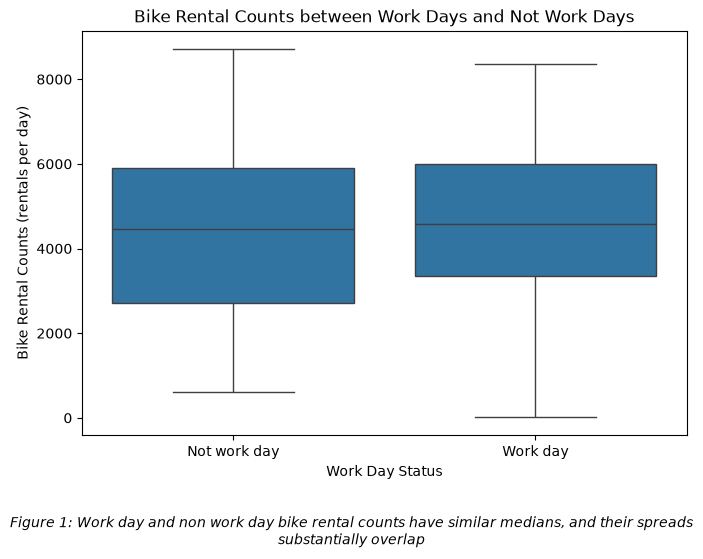

In [20]:
fig, ax = plt.subplots(
    figsize = (7,5)
)

sns.boxplot(
    data = bike_analysis,
    x = "work_day",
    y = "cnt",
    ax = ax
)

ax.set(
    title = "Bike Rental Counts between Work Days and Not Work Days",
    xlabel = "Work Day Status",
    ylabel = "Bike Rental Counts (rentals per day)"
)

plt.figtext(
    0.5, -0.1, 
    "Figure 1: Work day and non work day bike rental counts have similar medians, and their spreads substantially overlap", 
    ha="center", 
    fontsize=10, 
    style="italic",
    wrap=True
)

fig.tight_layout()

fig.savefig(
    "../figures/rental_counts_by_work_day_status.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()

## Plot 2 - Distribution of bike rental counts

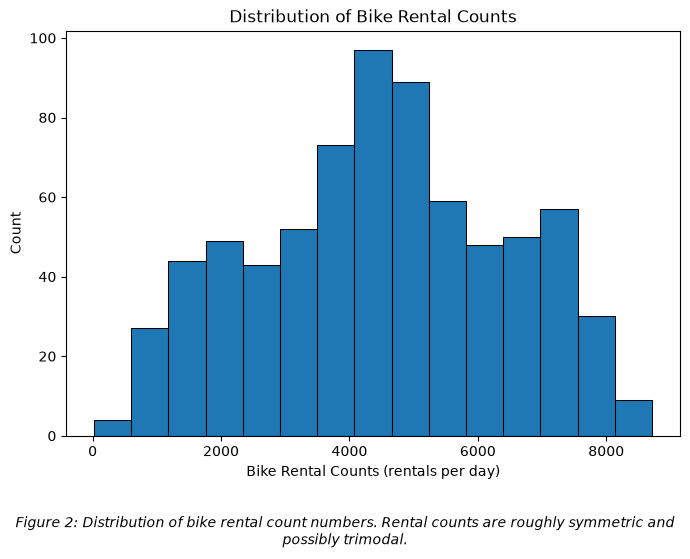

In [21]:
fig, ax = plt.subplots(
    figsize = (7,5)
)

plt.hist(
    bike_analysis["cnt"],
    bins = 15,
    edgecolor = "black",
    linewidth = 0.75
)

ax.set(
    title = "Distribution of Bike Rental Counts",
    xlabel = "Bike Rental Counts (rentals per day)",
    ylabel = "Count"
)

plt.figtext(
    0.5, -0.1, 
    "Figure 2: Distribution of bike rental count numbers. Rental counts are roughly symmetric and possibly trimodal.", 
    ha="center", 
    fontsize=10, 
    style="italic",
    wrap=True
)

fig.tight_layout()

fig.savefig(
    "../figures/rental_count_distribution.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()

## Plot 3 - Density of bike rental counts

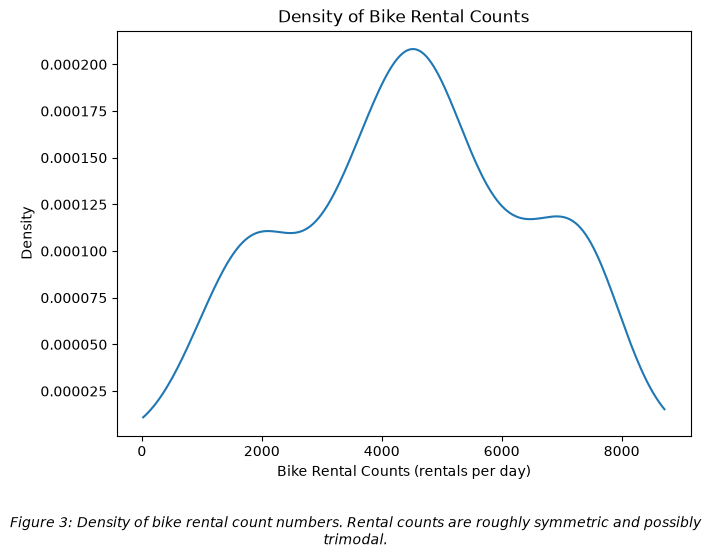

In [22]:
fig, ax = plt.subplots(
    figsize = (7,5)
)

sns.kdeplot(
    data = bike_analysis,
    x = "cnt",
    cut = 0,
    ax = ax
)

ax.set(
    title = "Density of Bike Rental Counts",
    xlabel = "Bike Rental Counts (rentals per day)",
    ylabel = "Density"
)

plt.figtext(
    0.5, -0.1, 
    "Figure 3: Density of bike rental count numbers. Rental counts are roughly symmetric and possibly trimodal.", 
    ha="center", 
    fontsize=10, 
    style="italic",
    wrap=True
)

fig.tight_layout()

fig.savefig(
    "../figures/rental_count_density.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()

## Plot 4 - Relationship between bike rental counts and temperature

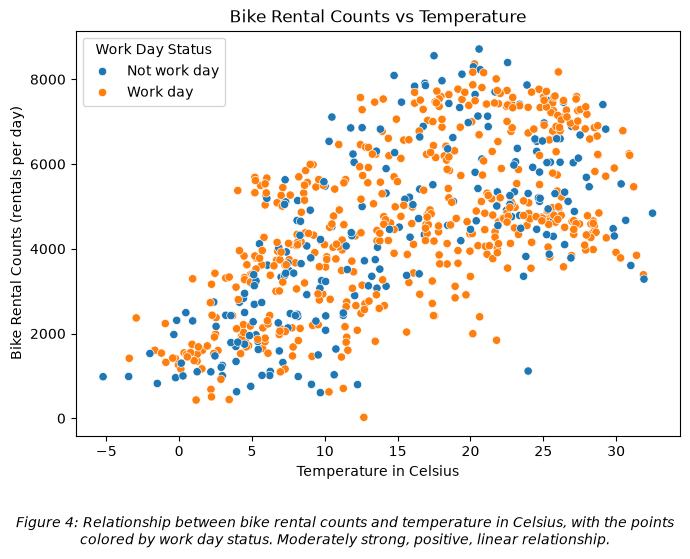

In [23]:
fig, ax = plt.subplots(
    figsize = (7,5)
)

sns.scatterplot(
    data = bike_analysis,
    x = "abs_temp",
    y = "cnt",
    hue = "work_day",
    ax = ax
)

ax.set(
    title = "Bike Rental Counts vs Temperature",
    xlabel = "Temperature in Celsius",
    ylabel = "Bike Rental Counts (rentals per day)"
)

ax.legend(
    title = "Work Day Status"
)

plt.figtext(
    0.5, -0.1, 
    "Figure 4: Relationship between bike rental counts and temperature in Celsius, with the points colored by work day status. Moderately strong, positive, linear relationship.", 
    ha="center", 
    fontsize=10, 
    style="italic",
    wrap=True
)

fig.tight_layout()

fig.savefig(
    "../figures/count_temp_relationship.png",
    dpi = 300,
    bbox_inches = "tight"
)

plt.show()